# Reproducing the reported tables and figures

This notebook rebuilds the tables and figures of the manuscript from the files in `results/` and `runs/`. Each section answers one question of the paper: how well the simulator reproduces the recorded recovery, whether training was healthy, how the policies compare, what the learned policy weights look like, and whether the conclusions survive changes in uncertain parameters.

The long computations (the calibration grid, PPO training, the FCR search and the sensitivity runs) are not repeated here, because they take from 15 minutes to an hour; the README lists their commands. The evaluation takes about one minute, so this notebook can rerun it when `RERUN_EVALUATION` is set to `True`.

In [1]:
import json
import os
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="Pandas requires version")   # numexpr version notice
import pandas as pd
from IPython.display import Image, display

import calibrate, health, report
%matplotlib inline

RERUN_EVALUATION = False   # True: rerun all 840 evaluation episodes (about 1 min on 14 cores)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 3)

## 1. Recorded recovery

The simulator is calibrated against the housing recovery recorded by BPBD NTB. The figure shows the share of damaged houses rebuilt in each region; day 0 is the 2018-08-19 earthquake. Almost no house is finished in the first 200 days, so the simulator needs a pre-construction delay. The regions then recover at different speeds, and a workforce limit can explain this, because the regions have different numbers of workers per damaged house.

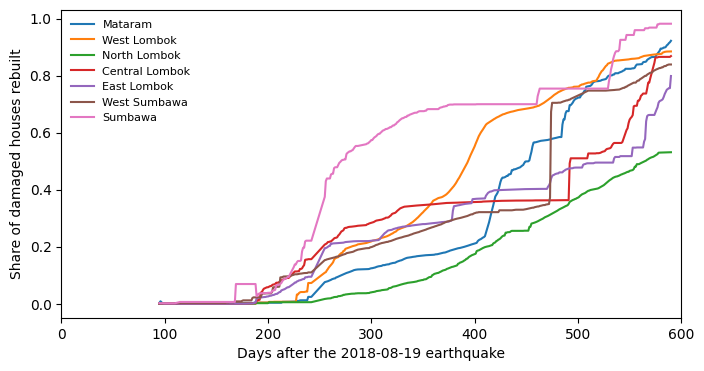

In [2]:
import matplotlib.pyplot as plt

obs = calibrate.observed()
fig, ax = plt.subplots(figsize=(8, 4))
for region, (days, share, _) in obs.items():
    ax.plot(days, share, label=calibrate.C.REGIONS[region].name)
ax.set(xlabel="Days after the 2018-08-19 earthquake", ylabel="Share of damaged houses rebuilt", xlim=(0, 600))
ax.legend(frameon=False, fontsize=8)
plt.show()

## 2. Calibration

The calibration searches the crew cap of each damage level, the repair-work scale and the stretch of the information batches. It compares the simulated recovery directly with the recorded history in Mataram and looks for the parameters with the smallest error; the other six regions are kept for validation. The table lists the ten best Mataram fits. The column `hc_ljf_minus_sjf` tells whether the workforce is ever scarce: when it is 0, every policy gives the same result.

In [3]:
top = pd.read_csv("results/calibration/top.csv")
top[["alpha", "c_minor", "c_moderate", "c_major", "lam", "fit30", "rmse_overall30", "hc_ljf_minus_sjf"]]

,alpha,c_minor,c_moderate,c_major,lam,fit30,rmse_overall30,hc_ljf_minus_sjf
0,4.0,1,2,6,2,0.063,0.047,0.000
1,4.0,1,2,5,2,0.066,0.047,0.000
2,5.0,1,2,6,1,0.066,0.045,0.587
3,5.0,1,2,5,1,0.066,0.046,0.497
4,6.0,2,2,6,1,0.067,0.064,14.315
5,3.0,1,1,6,2,0.068,0.058,0.000
6,3.0,1,1,5,2,0.069,0.057,0.000
7,6.0,2,2,5,1,0.069,0.062,14.731
8,3.0,1,1,4,2,0.070,0.056,0.000
9,4.0,1,2,4,2,0.070,0.046,0.000


The best fit (row 0, crew caps 1/2/6) leaves the workforce idle in five of the seven regions, so the order of repairs would not matter there. Therefore, the reported calibration takes row 4 (crew caps 2/2/6, repair-work scale 6, batches on days 0, 14 and 60): its Mataram fit is about 6% worse, but the workforce is scarce in every region and the validation regions fit best. The next cell shows the chosen values and the error in every region.

In [4]:
print(json.dumps(json.loads(Path("results/calibration/best.json").read_text()), indent=1))
pd.read_csv("results/calibration/validation.csv")

{
 "alpha": 6.0,
 "c_minor": 2.0,
 "c_moderate": 2.0,
 "c_major": 6.0,
 "lam": 1.0,
 "fit": 0.06739353611144286,
 "se": 0.00018989267701497857,
 "rmse_overall": 0.0640013361652038,
 "batches": [
  [
   0,
   0.3
  ],
  [
   14,
   0.35
  ],
  [
   60,
   0.35
  ]
 ],
 "seeds": "100-129"
}


,region,role,fit,se,rmse_overall,rmse_minor,rmse_moderate,rmse_major
0,Mataram,calibration,0.067,1.899e-04,0.064,0.084,0.045,0.076
1,West Lombok,validation,0.135,2.629e-04,0.075,0.101,0.202,0.162
2,North Lombok,validation,0.049,1.102e-04,0.075,0.009,0.010,0.101
3,Central Lombok,validation,0.161,1.711e-04,0.112,0.100,0.156,0.277
4,East Lombok,validation,0.141,2.137e-04,0.043,0.142,0.171,0.209
5,West Sumbawa,validation,0.119,2.670e-04,0.081,0.089,0.192,0.114
6,Sumbawa,validation,0.243,3.589e-04,0.236,0.226,0.361,0.148


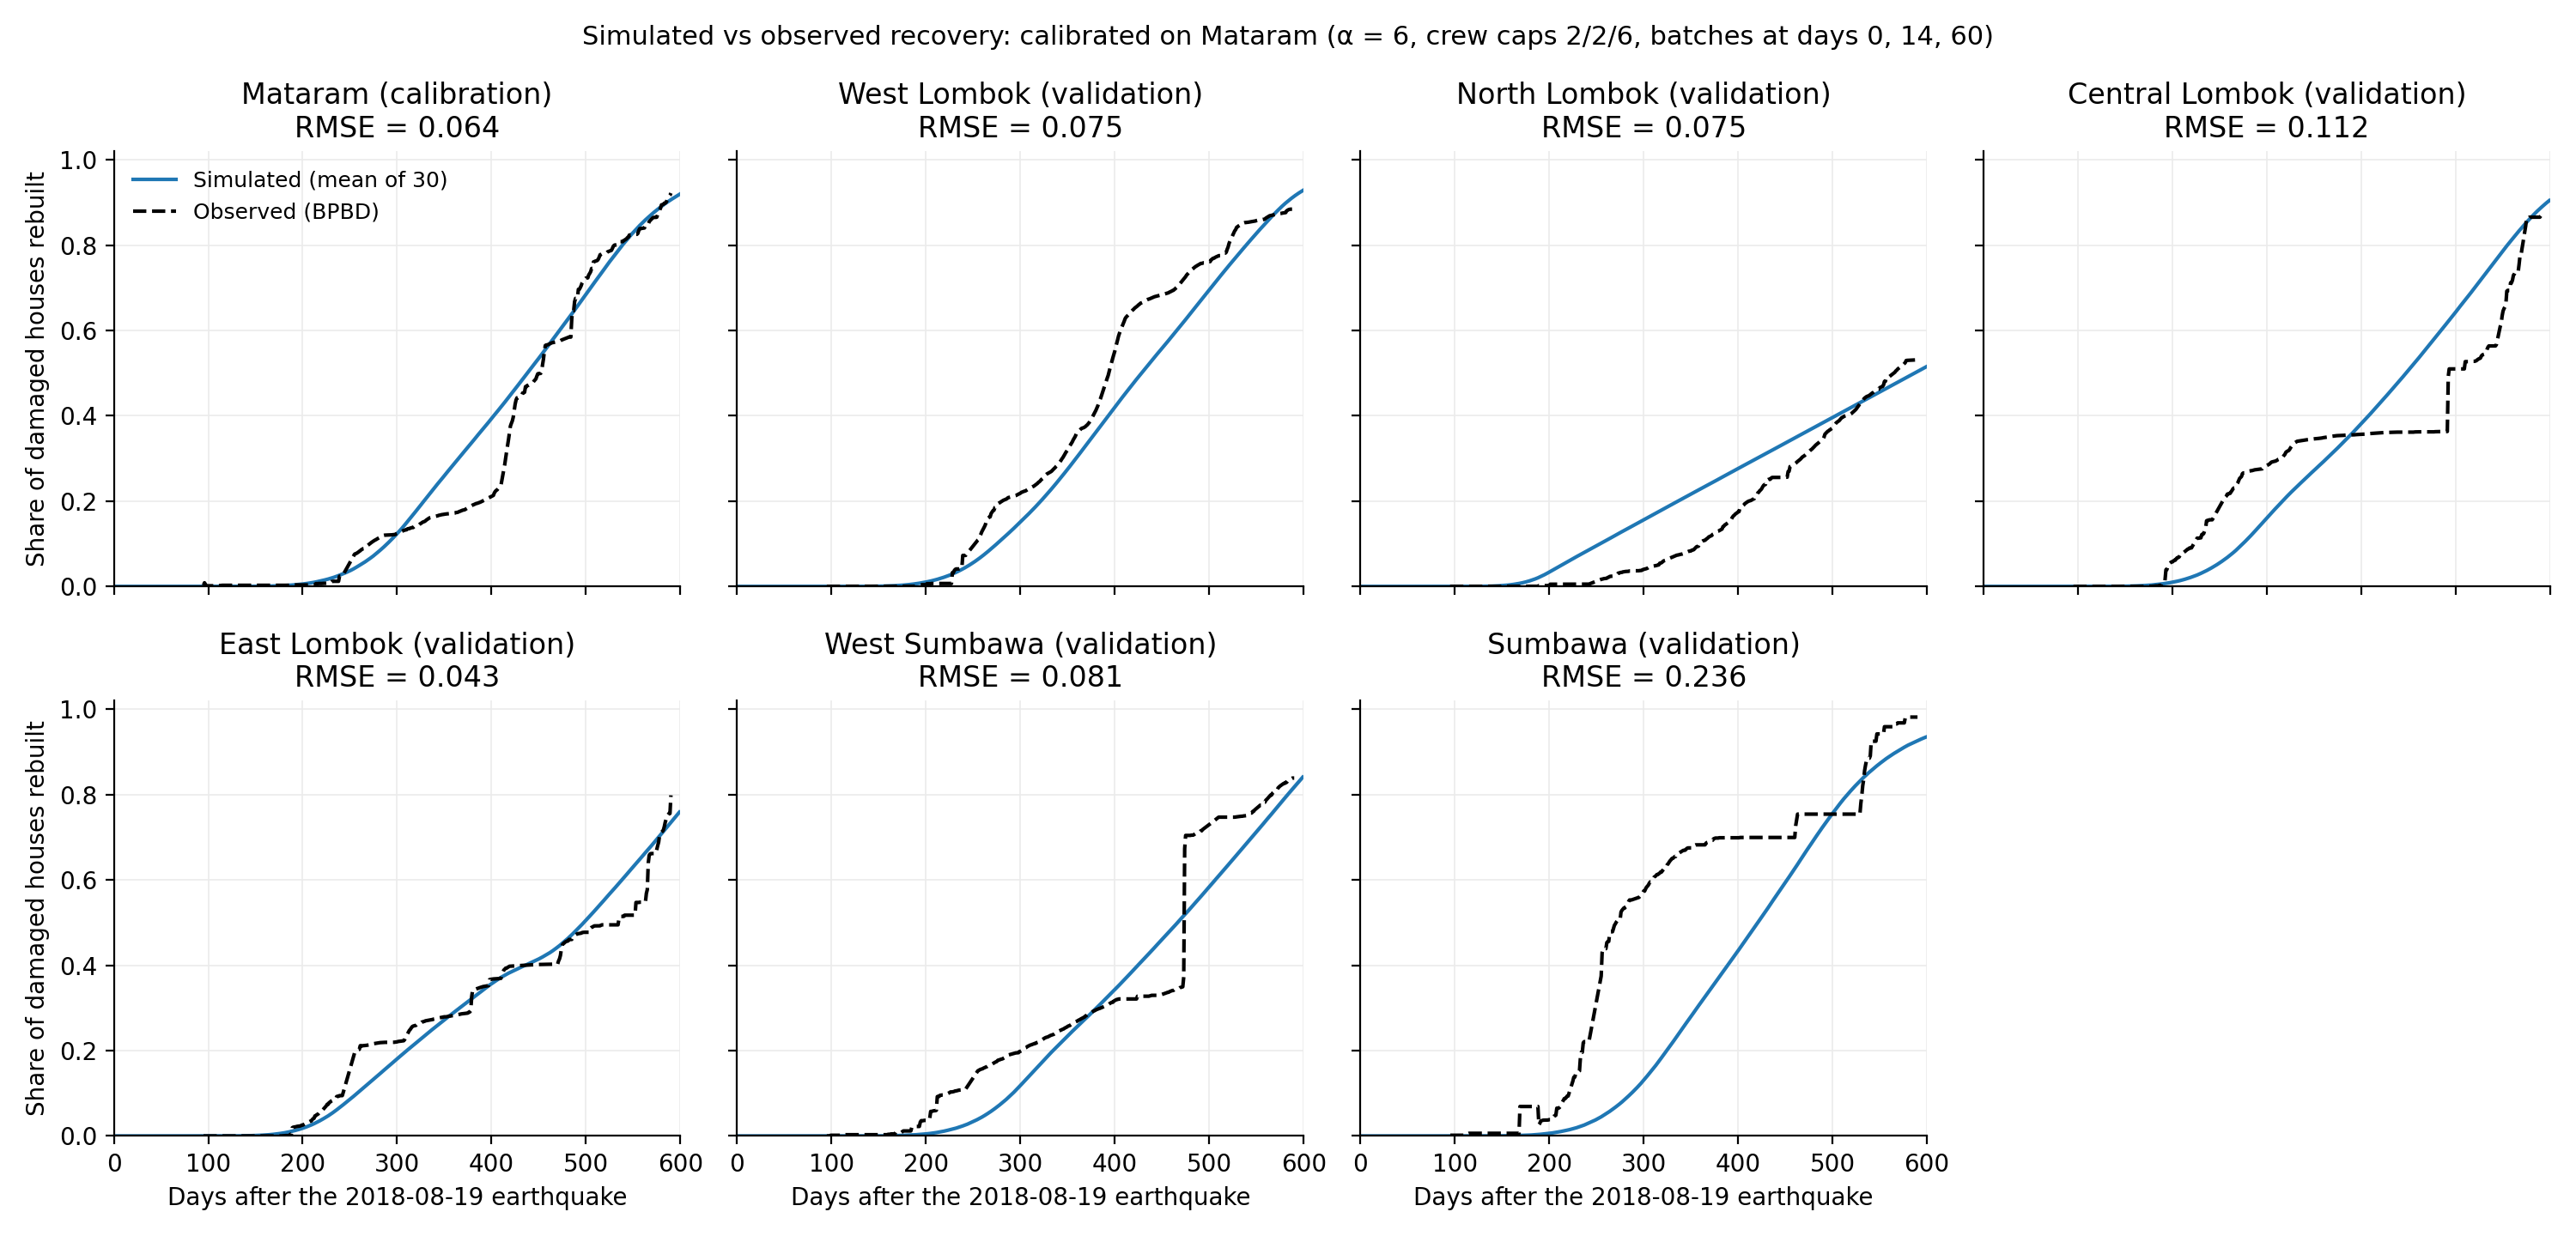

In [5]:
calibrate.plot(obs)   # redraws figures/calibration_*.png from the saved curves
display(Image("figures/calibration_regions.png"))

Sumbawa fits worst because its recorded curve rises steeply between days 250 and 300, much earlier than the other regions, and the simulator uses the same pre-construction delay in every region. The curves by damage level and the error surface are in `figures/calibration_by_damage.png` and `figures/calibration_rmse_surface.png`.

## 3. Training health

A training run counts as successful when its training signals are healthy. It does not need to beat a baseline, because whether the learned policy beats the fixed rules is what Section 4 tests. `health.py` checks the signals at 20% of training and at the end. The table shows the final check for each of the five seeds, and the figure shows the signals themselves: approx_kl stays far below 0.2, the explained variance is close to 1, and the policy entropy and standard deviation fall during training. Thus, all five runs are healthy.

In [6]:
rows = []
for k in range(5):
    h = json.loads(Path(f"runs/seed{k}/health.json").read_text())
    std = health.load(Path(f"runs/seed{k}"))["train/std"]
    rows.append({"seed": k, "healthy": h["healthy"], "kl_max": h["kl_max"], "ev_after_300k": h["ev_after_300k"],
                 "std_first": std.iloc[0], "std_last": std.iloc[-1],
                 "scenarios_never_trained": h["scenarios_never_trained"]})
pd.DataFrame(rows)

,seed,healthy,kl_max,ev_after_300k,std_first,std_last,scenarios_never_trained
0,0,True,0.009,1.0,1.010,0.863,0
1,1,True,0.010,1.0,1.008,0.765,0
2,2,True,0.010,1.0,1.003,0.813,0
3,3,True,0.009,1.0,1.009,0.810,0
4,4,True,0.010,1.0,1.005,0.880,0


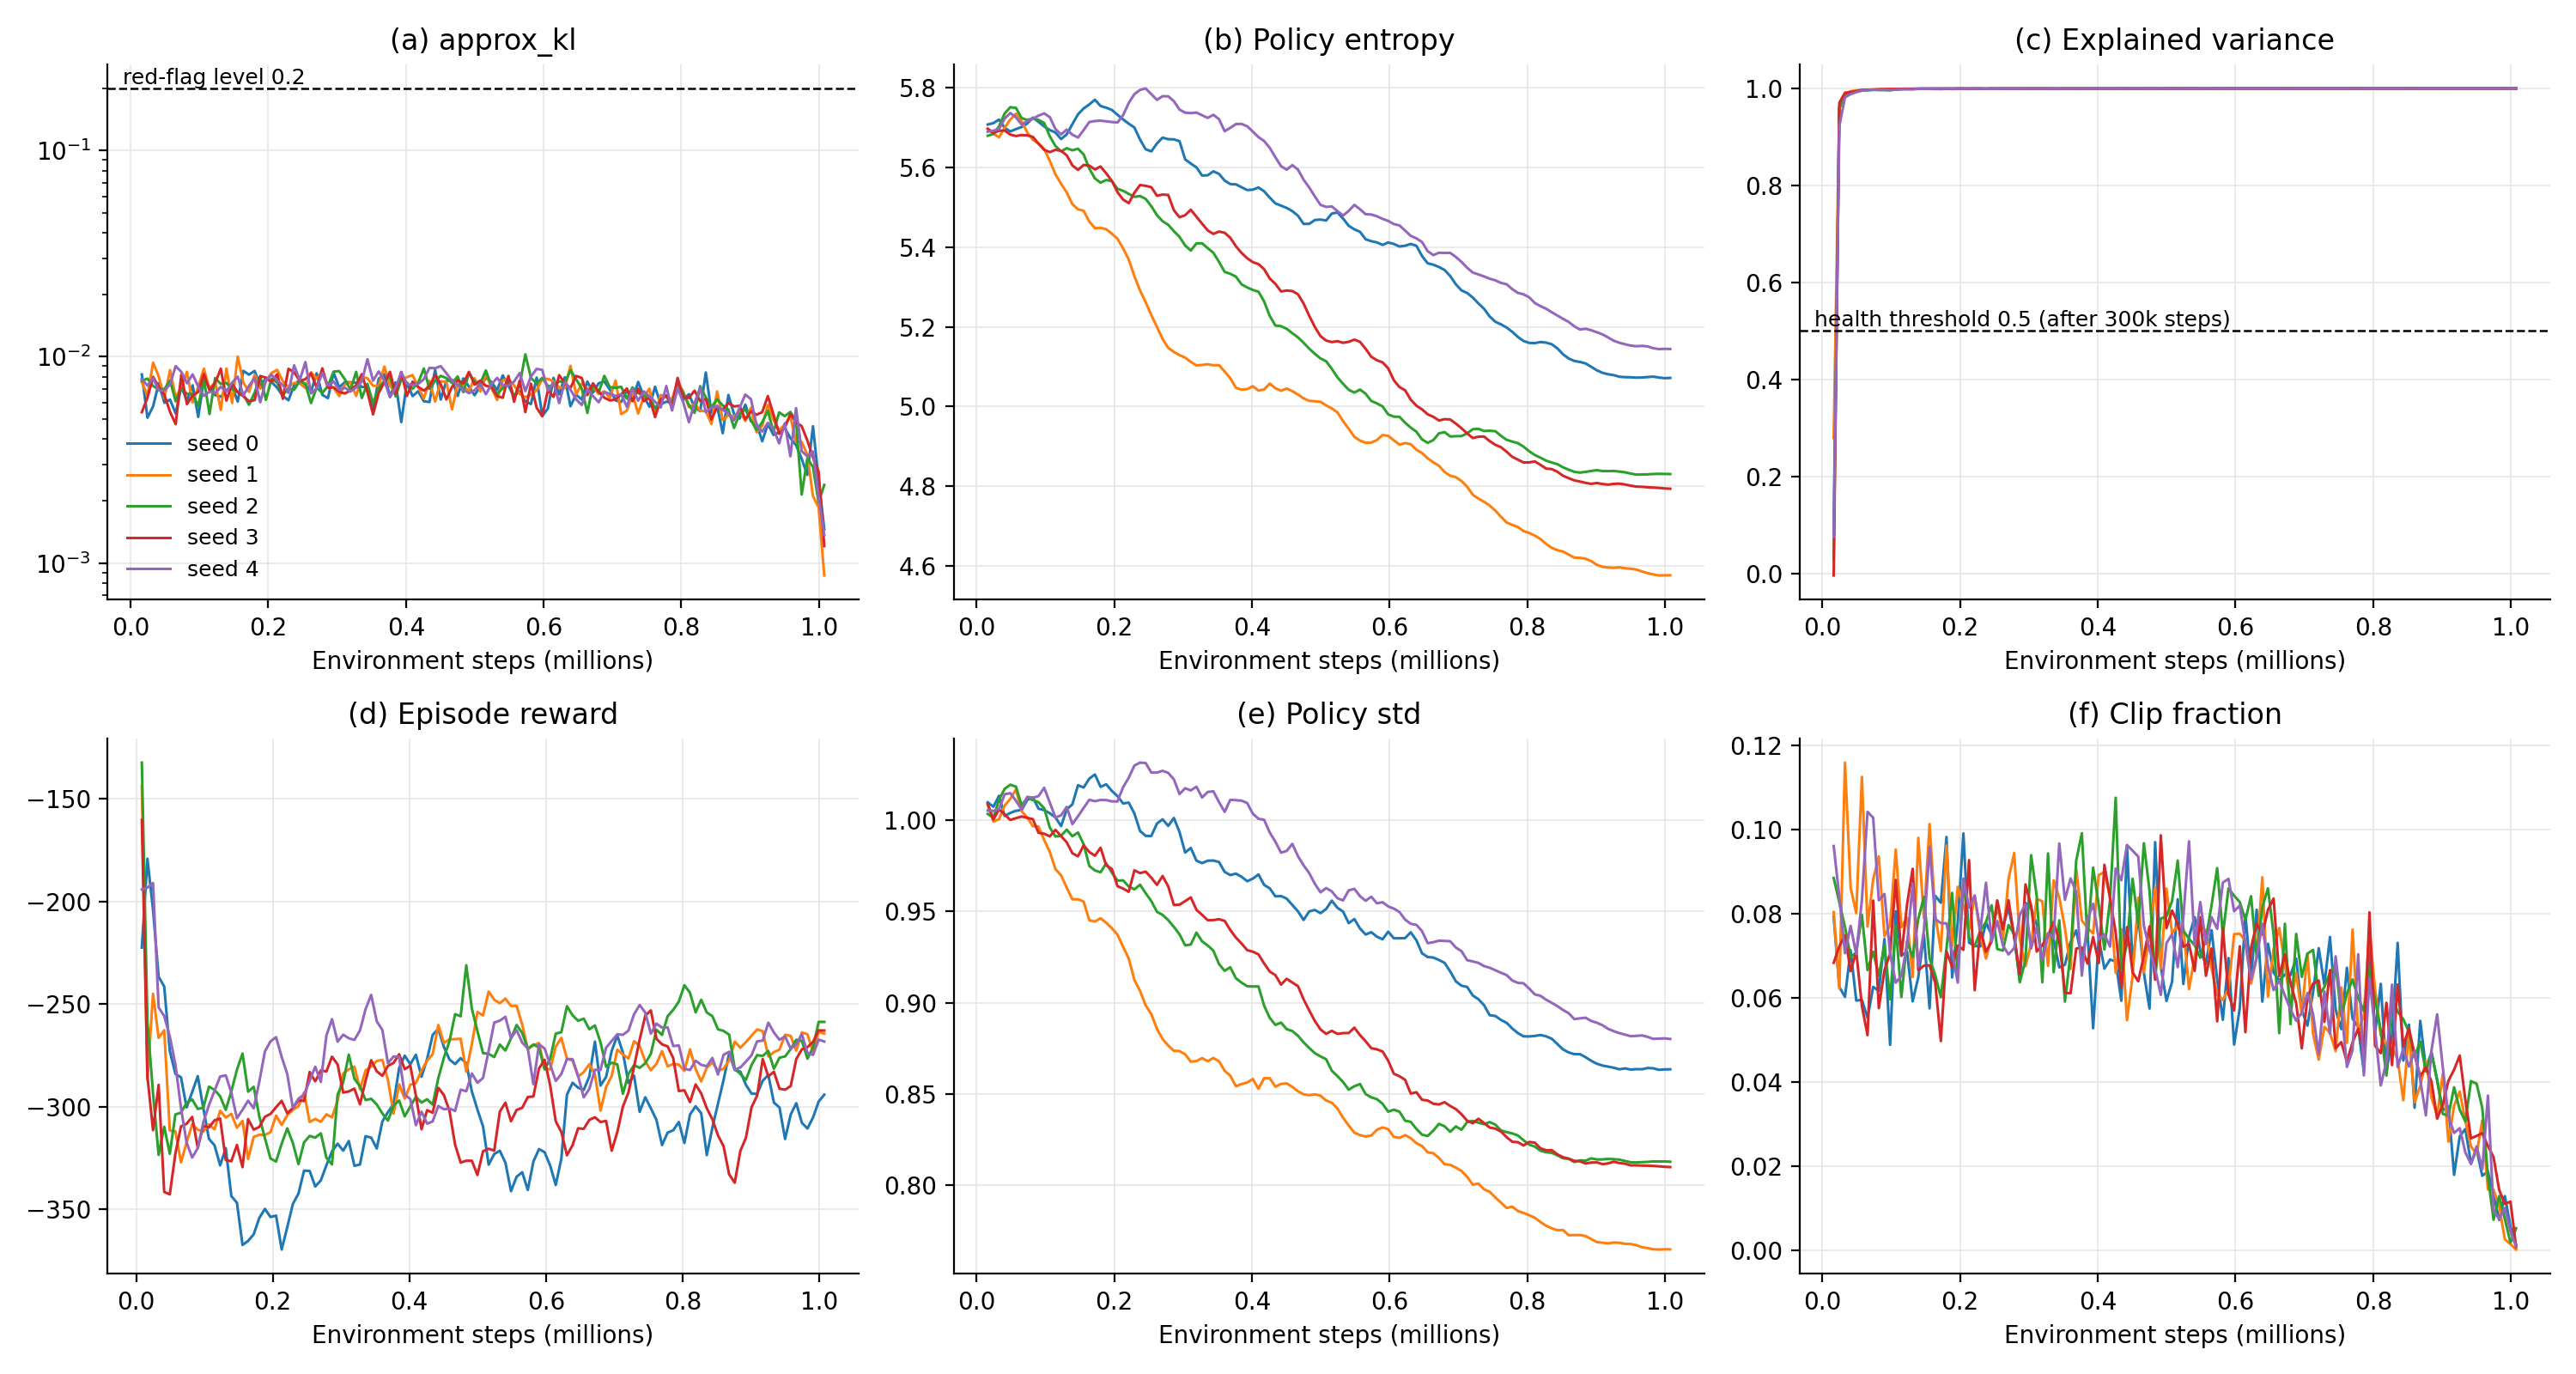

In [7]:
report.training_signals()
display(Image("figures/training_signals.png"))

## 4. Policy performance (Table 5)

All policies play the same 70 episodes: seven regions and environment seeds 1000-1009. Within a seed the regions get equal weight, and the table averages the ten seeds. The learned policy is the mean of the five trained models.

In [8]:
if RERUN_EVALUATION:
    subprocess.run([sys.executable, "-W", "ignore", "evaluate.py"], check=True, env={**os.environ, "OMP_NUM_THREADS": "1"})
episodes = report.tables(pd.read_csv("results/episodes.csv"))   # writes results/table5.csv and metrics_table.*

                             HC  Makespan  Mean recovery day  Mean wait  Mean completion  PL2 RT  PL2 completion  PL2 completion P90  Completion minor  Completion moderate  Completion major
FCR                     138.786  1175.286            441.315     39.865          136.399   0.008          95.485             153.854           114.000              171.345           123.242
SJF                     139.314  1175.957            441.287     39.830          136.371  37.003         132.490             270.447           116.358              172.267           120.194
FIFO                    161.345  1159.829            462.960     61.533          158.044  61.930         157.335             244.026           173.215              214.392           105.993
PriorityOnly            158.706  1147.686            461.237     59.796          156.321   0.000          95.484             153.484           161.071              192.607           114.665
Historical              165.186  1154.914         

FCR has the lowest holding cost, and SJF is close to it. The learned policy finishes all repairs about 21 days earlier than FCR, but it has a higher holding cost and a longer mean wait. Thus, no policy is best on every metric. The next table tests these differences: the learned policy (the five-model mean; `results/paired.csv` also has each model) is compared with FCR and with SJF in the same region and seed, and `excludes_0` marks a 95% interval that does not contain zero.

In [9]:
report.paired(episodes)   # writes results/paired.csv (every model) and prints the 5-model mean

                policy reference         metric    diff      lo      hi  excludes_0
Learned (5-model mean)       FCR             HC   3.472   3.101   3.843        True
Learned (5-model mean)       FCR      Mean wait   2.868   2.597   3.138        True
Learned (5-model mean)       FCR         PL2 RT  17.923  14.818  21.028        True
Learned (5-model mean)       FCR PL2 completion  17.938  14.891  20.986        True
Learned (5-model mean)       FCR       Makespan -21.466 -26.830 -16.101        True
Learned (5-model mean)       SJF             HC   2.944   2.536   3.352        True
Learned (5-model mean)       SJF      Mean wait   2.902   2.598   3.206        True
Learned (5-model mean)       SJF         PL2 RT -19.072 -24.049 -14.096        True
Learned (5-model mean)       SJF PL2 completion -19.067 -23.981 -14.152        True
Learned (5-model mean)       SJF       Makespan -22.137 -27.375 -16.899        True


Every interval excludes zero. Thus, the learned policy has a higher holding cost and a longer mean wait than FCR and SJF, and it finishes all repairs earlier than both. It gives medical facilities workers later than FCR but earlier than SJF.

## 5. Learned weights

Because every policy acts through the same four weights, the learned policy can be compared with the fixed rules attribute by attribute. A day's weights change who gets workers only on a contested day: after crews that started short are filled, the free workers cannot cover the crew caps of all candidates, at least two candidates compete, and the attribute differs among them. On the other days every weight vector gives the same dispatch.

Panel (a) averages the weights over all decision days and describes what the models usually output. Panel (b) averages them over contested days only and describes how the models score when workers are short. The points show each training seed.


Learned weights [work, wait, priority, damage]: all days, contested days, contested share
          all                        contested                        contested share                       
       w_work w_wait  w_pri w_damage    w_work w_wait  w_pri w_damage          w_work w_wait  w_pri w_damage
policy                                                                                                      
PPO0    0.013 -0.002 -0.029    0.125    -0.991 -0.414  0.037   -0.817           0.309  0.308  0.229    0.286
PPO1   -0.044 -0.001  0.163   -0.048    -0.956 -0.209 -0.097   -0.109           0.290  0.289  0.213    0.278
PPO2   -0.156 -0.208  0.195    0.452    -0.974 -0.557  0.355   -0.472           0.300  0.299  0.169    0.286
PPO3   -0.163  0.086  0.003   -0.086    -0.970 -0.198  0.297   -0.451           0.300  0.299  0.157    0.279
PPO4   -0.205  0.039 -0.171   -0.066    -0.962 -0.214  0.963   -0.609           0.299  0.298  0.123    0.293


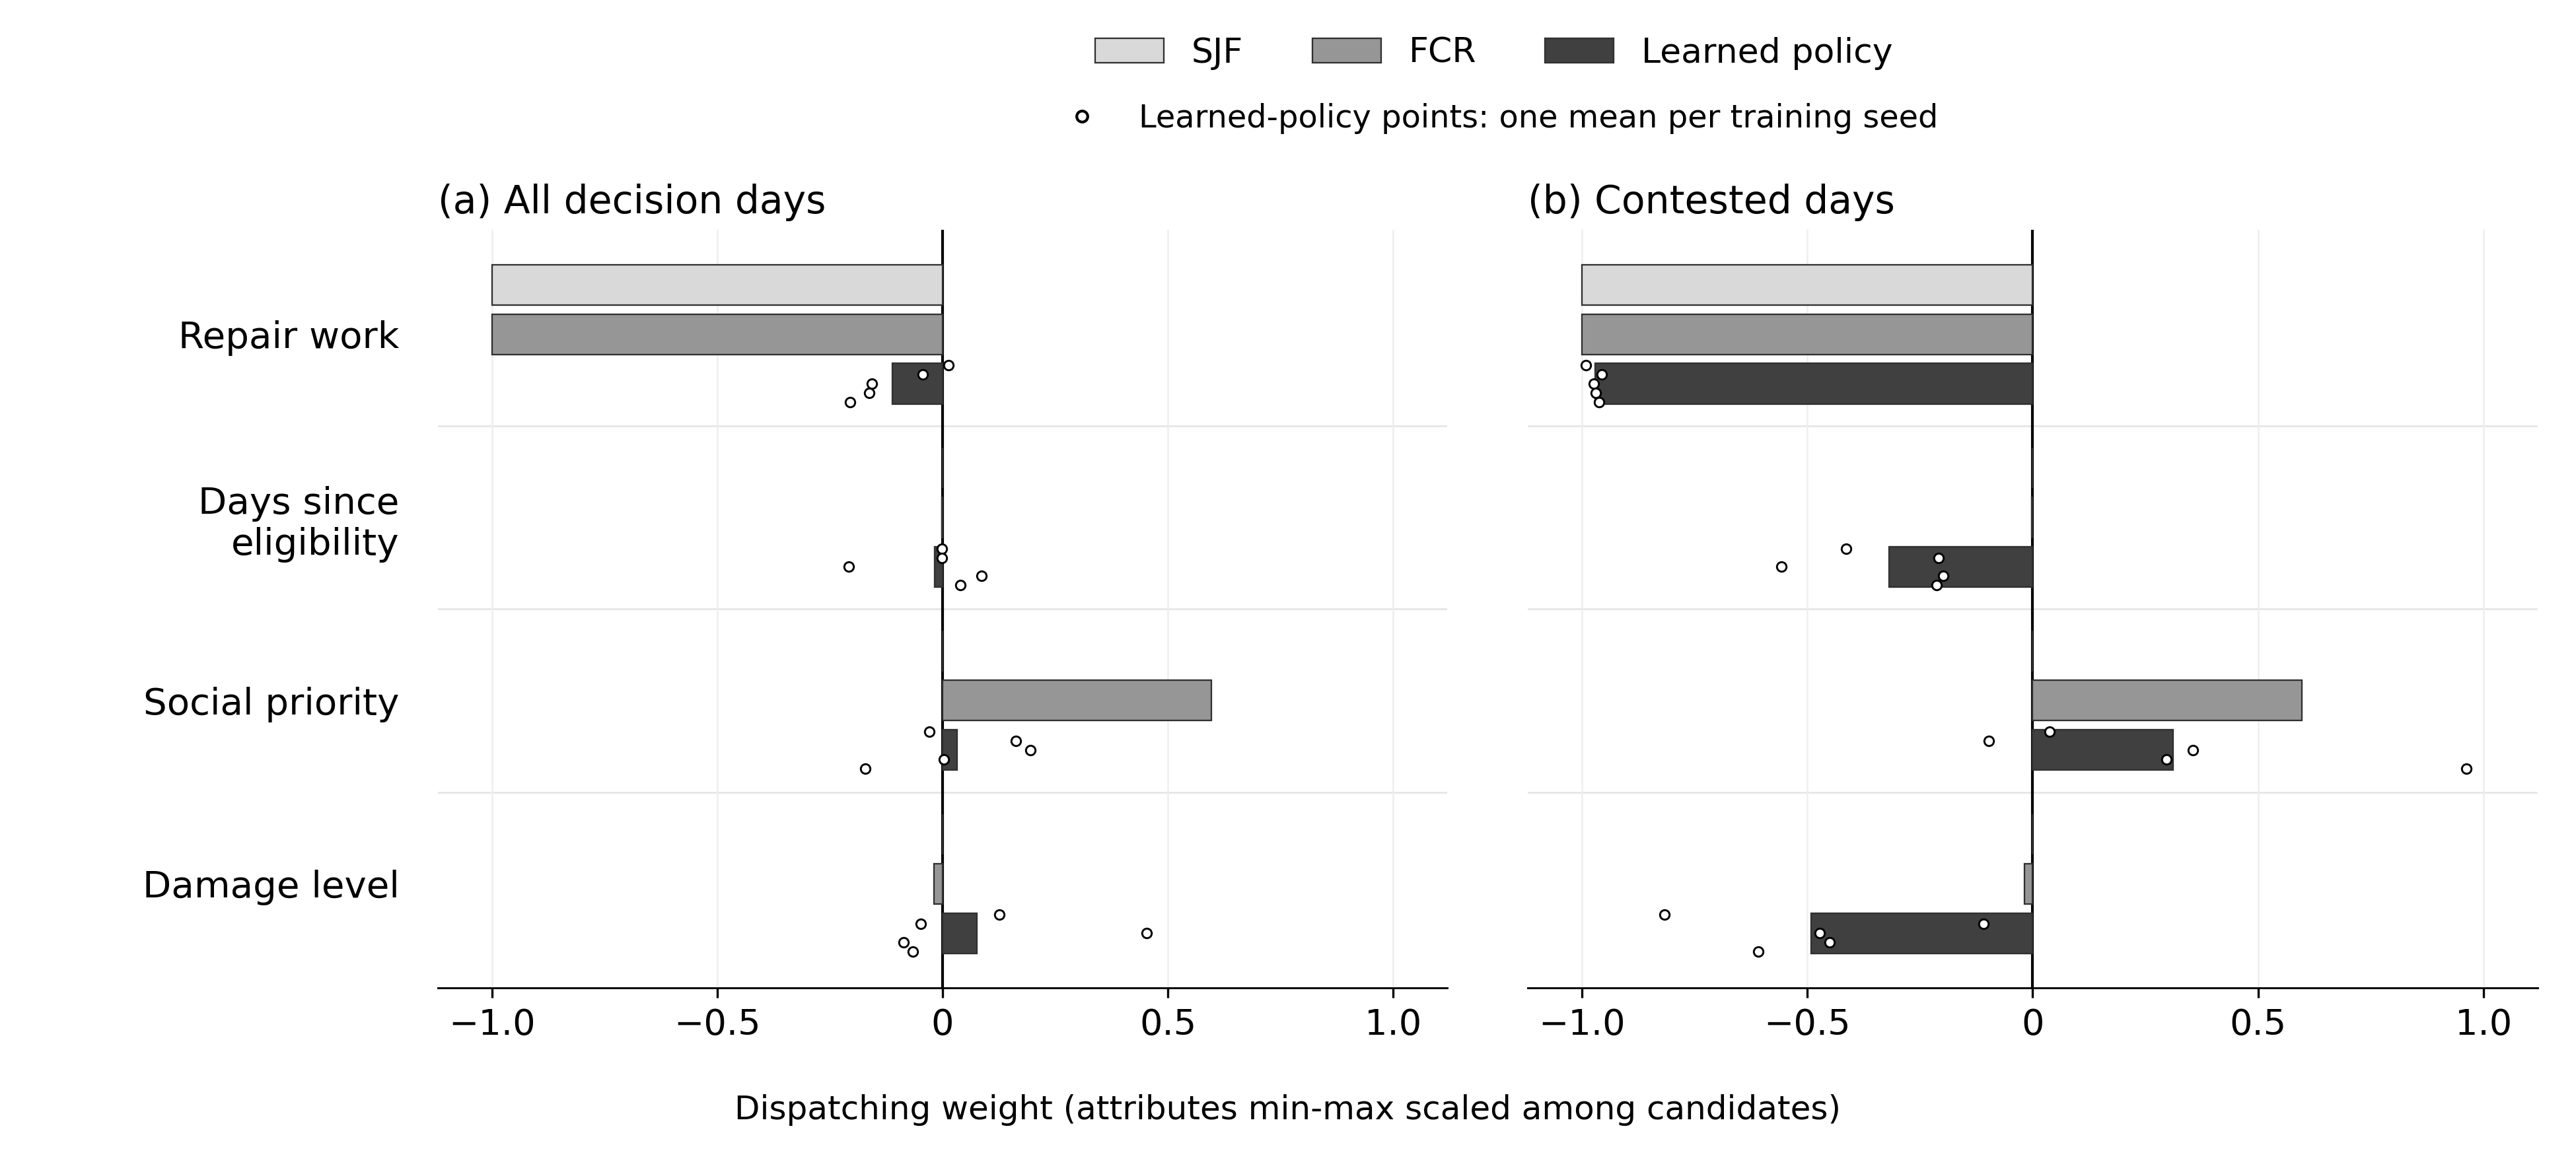

In [10]:
report.weight_comparison(episodes)
display(Image("figures/policy_weights.png"))

Over all days the weights are small and their signs differ between models, because about 70% of the decision days involve no choice and the outputs on those days do not affect the reward. On contested days (about 30% of decision days), all five models give repair work a weight between -0.99 and -0.96, close to SJF and FCR, and negative weights to damage level and days since eligibility: they prefer smaller, less damaged and more recently eligible houses. The social-priority weight still differs between models (-0.10 to 0.96). The model with the largest contested priority weight (seed 4, 0.96) gives medical facilities workers earliest, although its all-day mean is negative. However, seed 3 has a positive contested priority weight (0.30) and the latest PL2 response, so the weights alone do not determine the outcome; how the scores change the actual ranking and dispatch has to be checked directly.

## 6. Sensitivity analysis

The workforce, the batch days and shares, the absence rate, the return probability of absent workers and the progress noise are uncertain. The sensitivity analysis changes them in 44 settings and checks seven conclusions that were written down before the first run. A conclusion holds in a setting when the 95% interval of the paired difference lies entirely on the claimed side of zero.

In [11]:
checks = pd.read_csv("results/sensitivity/checks.csv")
checks.groupby("check").agg(settings_holding=("holds", "sum"), settings=("holds", "size"))

,settings_holding,settings
check,,
C1 HC: FCR < Learned,44,44
C2 HC: Learned < Random,44,44
C3 HC: SJF < Historical,44,44
C4 Makespan: LJF < SJF,44,44
C5 HC: SJF < LJF,44,44
C6 PL2 RT: Learned < SJF,44,44
C7 Mean wait: FCR < Learned,44,44


All seven conclusions hold in all 44 settings. However, the holding-cost gap between FCR and the learned policy depends on the workforce: the heat maps below show that it grows when the workforce is halved or absences are more frequent.

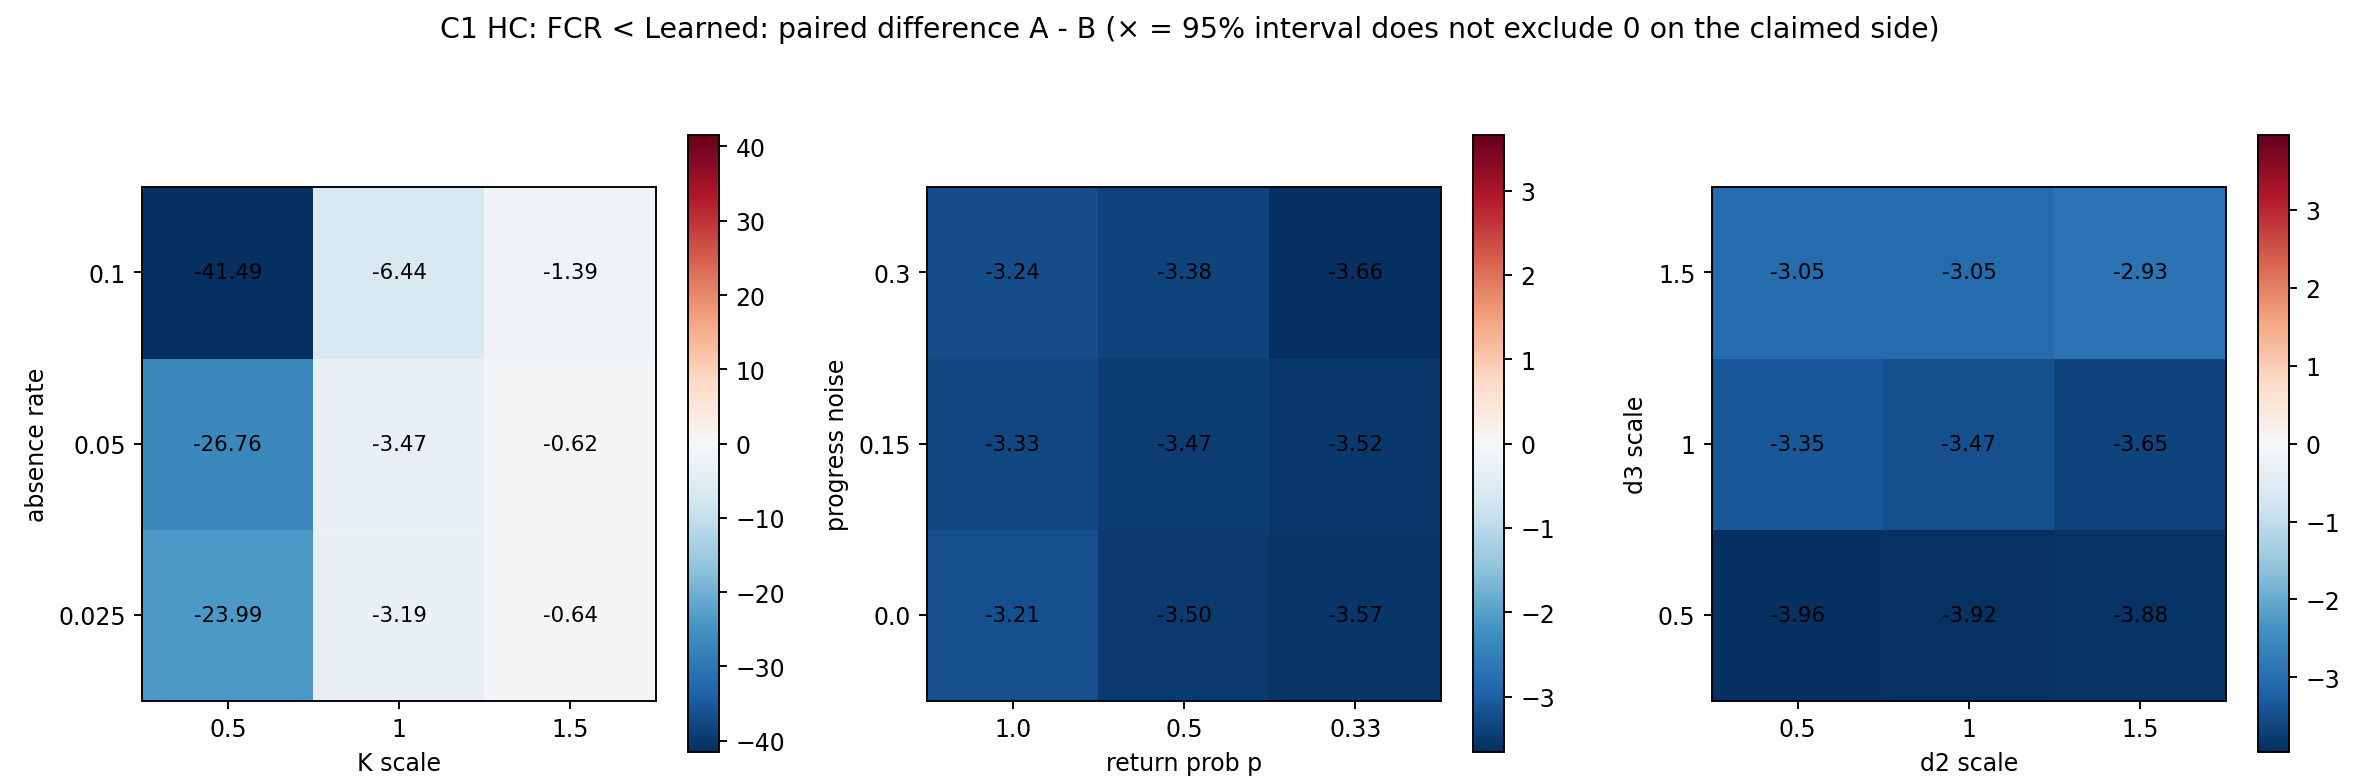

In [12]:
display(Image("figures/sensitivity_C1_HC.png"))

The holding-cost weights (1, 2 and 5 for priority levels 0, 1 and 2) are a design choice as well. The table recomputes the holding cost of every policy in the main evaluation under three other weightings: equal weights, steeper priority weights (1/5/25), and weights by damage level (1/2/5).

In [13]:
pd.read_csv("results/episodes.csv").groupby("policy")[["holding_cost", "hc_pl_1_1_1", "hc_pl_1_5_25", "hc_damage_1_2_5"]].mean().sort_values("holding_cost")

,holding_cost,hc_pl_1_1_1,hc_pl_1_5_25,hc_damage_1_2_5
policy,,,,
FCR,138.786,136.399,148.808,336.639
SJF,139.314,136.371,151.616,333.207
PPO4,140.237,137.848,150.268,364.473
PPO0,141.238,138.223,153.906,367.447
PPO2,142.584,139.531,155.282,352.137
PPO1,142.616,139.674,154.873,335.104
PPO3,144.615,141.075,159.279,346.743
PriorityOnly,158.706,156.321,168.725,365.177
Random,158.965,156.533,169.168,388.617


Under all three weightings, SJF or FCR still has the lowest holding cost. However, under weights by damage level the Historical rule (major damage first) moves close to FCR, so the ranking of the other policies depends on the cost weights.